# Retail Customer Segmentation: RFM Analysis

**Business question:** Which customers drive this online retailer's revenue, which are growing, and which are slipping away, and where should the marketing budget go?

**Data:** UCI Online Retail dataset, 541,909 transactions from a UK-based online gift retailer (Dec 2010 – Dec 2011).
Download `data.csv` from [Kaggle](https://www.kaggle.com/datasets/carrie1/ecommerce-data) and place it in the `data/` folder before running.

**Workflow:** data quality assessment → data cleaning → outlier analysis → business KPIs → RFM features → K-Means clustering → segment profiling → recommendations

In [1]:
import warnings
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
IMG_DIR = 'images'

df_raw = pd.read_csv('data/data.csv', encoding='ISO-8859-1')
print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head()

Dataset shape: 541,909 rows x 8 columns
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 1. Data quality assessment

In [2]:
invoice_dates = pd.to_datetime(df_raw['InvoiceDate'])
print(f"Date range: {invoice_dates.min().date()} to {invoice_dates.max().date()}")

missing = df_raw.isnull().sum()
missing_df = pd.DataFrame({'Count': missing, 'Percent': (missing / len(df_raw) * 100).round(1)})
print("\n--- Missing values ---")
print(missing_df[missing_df['Count'] > 0].to_string())

checks = {
    'Negative quantity (returns)': (df_raw['Quantity'] < 0).sum(),
    'Zero/negative unit price': (df_raw['UnitPrice'] <= 0).sum(),
    'Cancelled invoices (start with C)': df_raw['InvoiceNo'].astype(str).str.startswith('C').sum(),
    'Duplicate rows': df_raw.duplicated().sum(),
}
print("\n--- Integrity issues ---")
for key, value in checks.items():
    print(f"{key:36s} {value:>8,} ({value / len(df_raw) * 100:.1f}%)")

Date range: 2010-12-01 to 2011-12-09

--- Missing values ---
              Count  Percent
Description    1454      0.3
CustomerID   135080     24.9



--- Integrity issues ---
Negative quantity (returns)            10,624 (2.0%)
Zero/negative unit price                2,517 (0.5%)
Cancelled invoices (start with C)       9,288 (1.7%)
Duplicate rows                          5,268 (1.0%)


## 2. What the data quality issues reveal

Before removing problem rows, it is worth asking what they say about the business.

- **Returns:** many negative-quantity rows are warehouse adjustments (damaged, lost, test entries), not customers sending items back. Separating the two gives a truer return rate.
- **Missing customer IDs:** if they are concentrated in one country, that points to a checkout or system issue rather than random gaps.

In [3]:
returns = df_raw[df_raw['Quantity'] < 0].copy()

noise_keywords = ['damage', 'check', 'thrown', 'throw', 'smudge', 'unsaleable',
                  'destroyed', 'crushed', 'wet', 'lost', '?', 'adjust',
                  'incorrect', 'mouldy', 'rusty', 'broken', 'manual',
                  'wrongly', 'wrong', 'sold as set', 'dotcom', 'display',
                  'sample', 'test', 'amazon', 'ebay', 'counted', 'label',
                  'alan', 'barry', 'john', 'mark', 'dave', 'mixed up',
                  'missing', 'mailout', 'allocat', 'discount', 'postage',
                  'carriage', 'bank charges', 'packing']

returns['IsWarehouseAdj'] = returns['Description'].fillna('').str.lower().apply(
    lambda text: any(keyword in text for keyword in noise_keywords)
)
warehouse_adj = returns[returns['IsWarehouseAdj']]
customer_returns = returns[~returns['IsWarehouseAdj']]
bulk_returns = customer_returns[customer_returns['Quantity'].abs() > 1000]
genuine_returns = customer_returns[customer_returns['Quantity'].abs() <= 1000]

print(f"Return rows: {len(returns):,}")
print(f"  Customer returns:      {len(customer_returns):,} ({len(customer_returns) / len(returns) * 100:.0f}%)")
print(f"  Warehouse adjustments: {len(warehouse_adj):,} ({len(warehouse_adj) / len(returns) * 100:.0f}%)")
print(f"  Bulk corrections (>1,000 units): {len(bulk_returns):,}")
print(f"  Genuine customer returns: {len(genuine_returns):,}")

missing_cust = df_raw[df_raw['CustomerID'].isnull()]
missing_rev = (missing_cust['Quantity'] * missing_cust['UnitPrice']).sum()
total_rev_raw = (df_raw['Quantity'] * df_raw['UnitPrice']).sum()
print(f"\nRows without CustomerID: {len(missing_cust):,} ({len(missing_cust) / len(df_raw) * 100:.1f}%)")
print(f"Revenue from unidentified customers: £{missing_rev:,.0f} ({missing_rev / total_rev_raw * 100:.1f}% of total)")

print("\nMissing CustomerID by country (top 3):")
by_country = missing_cust['Country'].value_counts()
for key, value in by_country.head(3).items():
    print(f"  {key:12s} {value:>8,} ({value / len(missing_cust) * 100:.1f}%)")

Return rows: 10,624
  Customer returns:      9,579 (90%)
  Warehouse adjustments: 1,045 (10%)
  Bulk corrections (>1,000 units): 16
  Genuine customer returns: 9,563

Rows without CustomerID: 135,080 (24.9%)
Revenue from unidentified customers: £1,447,682 (14.9% of total)

Missing CustomerID by country (top 3):
  United Kingdom  133,600 (98.9%)
  EIRE              711 (0.5%)
  Hong Kong         288 (0.2%)


**Takeaways**
- Roughly 9 in 10 negative-quantity rows are genuine customer returns; the rest are internal adjustments and should not count toward the return rate.
- Almost all missing customer IDs come from the UK, which suggests a UK checkout capture gap. Recommendation: make customer ID capture mandatory at checkout.
- Neither returns nor unidentified transactions can be attributed to a customer, so both are excluded from the RFM analysis.

## 3. Data cleaning

In [4]:
df = df_raw.copy()
initial_rows = len(df)

df = df[df['CustomerID'].notna()]
print(f"1. Removed missing CustomerID:       {initial_rows - len(df):>8,} rows")

before = len(df)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[df['Quantity'] > 0]
print(f"2. Removed returns & cancellations:  {before - len(df):>8,} rows")

before = len(df)
df = df[df['UnitPrice'] > 0]
print(f"3. Removed zero/negative prices:     {before - len(df):>8,} rows")

before = len(df)
df = df.drop_duplicates()
print(f"4. Removed duplicates:               {before - len(df):>8,} rows")

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['CustomerID'] = df['CustomerID'].astype(int)
df['Revenue'] = df['Quantity'] * df['UnitPrice']

print(f"\nBefore: {initial_rows:,} rows | After: {len(df):,} rows | Retained: {len(df) / initial_rows * 100:.1f}%")
print(f"Customers: {df['CustomerID'].nunique():,} | Orders: {df['InvoiceNo'].nunique():,} | Products: {df['StockCode'].nunique():,}")

1. Removed missing CustomerID:        135,080 rows


2. Removed returns & cancellations:     8,905 rows
3. Removed zero/negative prices:           40 rows


4. Removed duplicates:                  5,192 rows

Before: 541,909 rows | After: 392,692 rows | Retained: 72.5%
Customers: 4,338 | Orders: 18,532 | Products: 3,665


## 4. Outlier analysis

Wholesale orders can distort averages. This step measures how heavy the tails of Revenue and Quantity are, to decide how to treat them later.

--- Revenue ---
  IQR bounds: [-17.32, 42.07]
  Outlier rows: 31,231 (8.0%)
  Mean / median: 22.63 / 12.45
  p95 / p99 / max: 67.50 / 203.52 / 168,469.60
--- Quantity ---
  IQR bounds: [-13.00, 27.00]
  Outlier rows: 25,616 (6.5%)
  Mean / median: 13.12 / 6.00
  p95 / p99 / max: 36.00 / 120.00 / 80,995.00


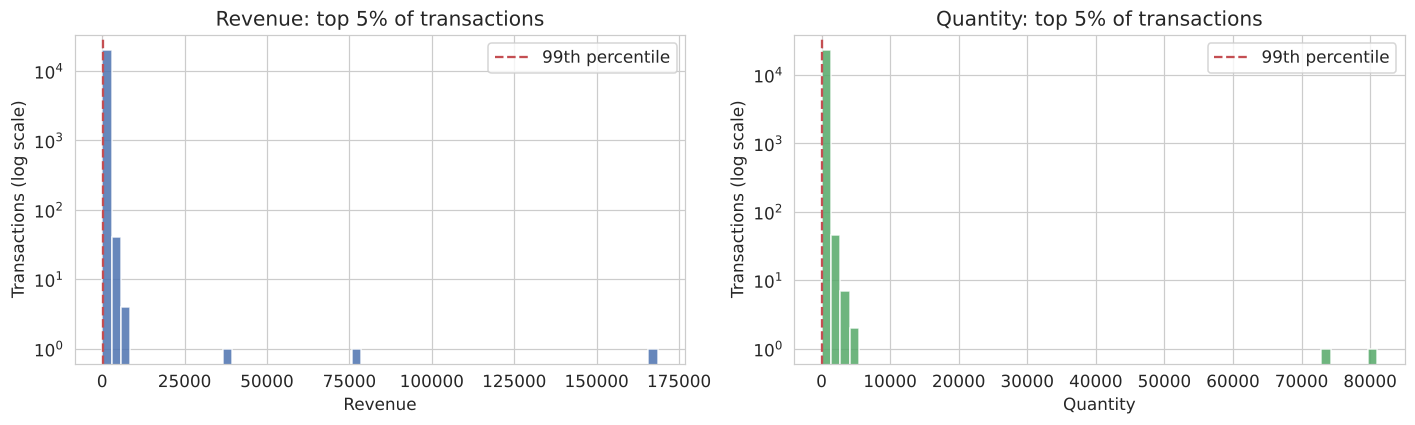

In [5]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

for col in ['Revenue', 'Quantity']:
    series = df[col]
    low, high = iqr_bounds(series)
    outliers = series[(series < low) | (series > high)]
    print(f"--- {col} ---")
    print(f"  IQR bounds: [{low:,.2f}, {high:,.2f}]")
    print(f"  Outlier rows: {len(outliers):,} ({len(outliers) / len(series) * 100:.1f}%)")
    print(f"  Mean / median: {series.mean():,.2f} / {series.median():,.2f}")
    print(f"  p95 / p99 / max: {series.quantile(0.95):,.2f} / {series.quantile(0.99):,.2f} / {series.max():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, color in zip(axes, ['Revenue', 'Quantity'], ['#4C72B0', '#55A868']):
    tail = df[df[col] >= df[col].quantile(0.95)][col]
    ax.hist(tail, bins=60, color=color, alpha=0.85)
    ax.axvline(df[col].quantile(0.99), color='#C44E52', linestyle='--', label='99th percentile')
    ax.set_yscale('log')
    ax.set_title(f'{col}: top 5% of transactions')
    ax.set_xlabel(col)
    ax.set_ylabel('Transactions (log scale)')
    ax.legend()
plt.tight_layout()
plt.show()

**Decision:** mean order value is inflated by a small number of wholesale orders, so median order value is reported alongside it. For RFM, Recency (dates) and Frequency (order counts) are not affected by unit outliers; Monetary is capped at the 99th percentile **for clustering only**. Segment revenue is always reported from actual, uncapped spend.

## 5. Business KPIs

In [6]:
total_revenue = df['Revenue'].sum()
total_orders = df['InvoiceNo'].nunique()
total_customers = df['CustomerID'].nunique()
order_values = df.groupby('InvoiceNo')['Revenue'].sum()

orders_per_customer = df.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_rate = (orders_per_customer > 1).mean() * 100

spend_per_customer = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)
top_10_share = spend_per_customer.head(int(total_customers * 0.1)).sum() / total_revenue * 100

print(f"Total revenue:          £{total_revenue:,.0f}")
print(f"Orders:                 {total_orders:,}")
print(f"Customers:              {total_customers:,}")
print(f"Avg order value:        £{order_values.mean():,.2f}")
print(f"Median order value:     £{order_values.median():,.2f}")
print(f"Repeat customer rate:   {repeat_rate:.1f}%")
print(f"One-time buyers:        {(orders_per_customer == 1).sum():,} ({100 - repeat_rate:.1f}%)")
print(f"Top 10% revenue share:  {top_10_share:.1f}%")

Total revenue:          £8,887,209
Orders:                 18,532
Customers:              4,338
Avg order value:        £479.56
Median order value:     £302.57
Repeat customer rate:   65.6%
One-time buyers:        1,493 (34.4%)
Top 10% revenue share:  61.4%


## 6. Business overview

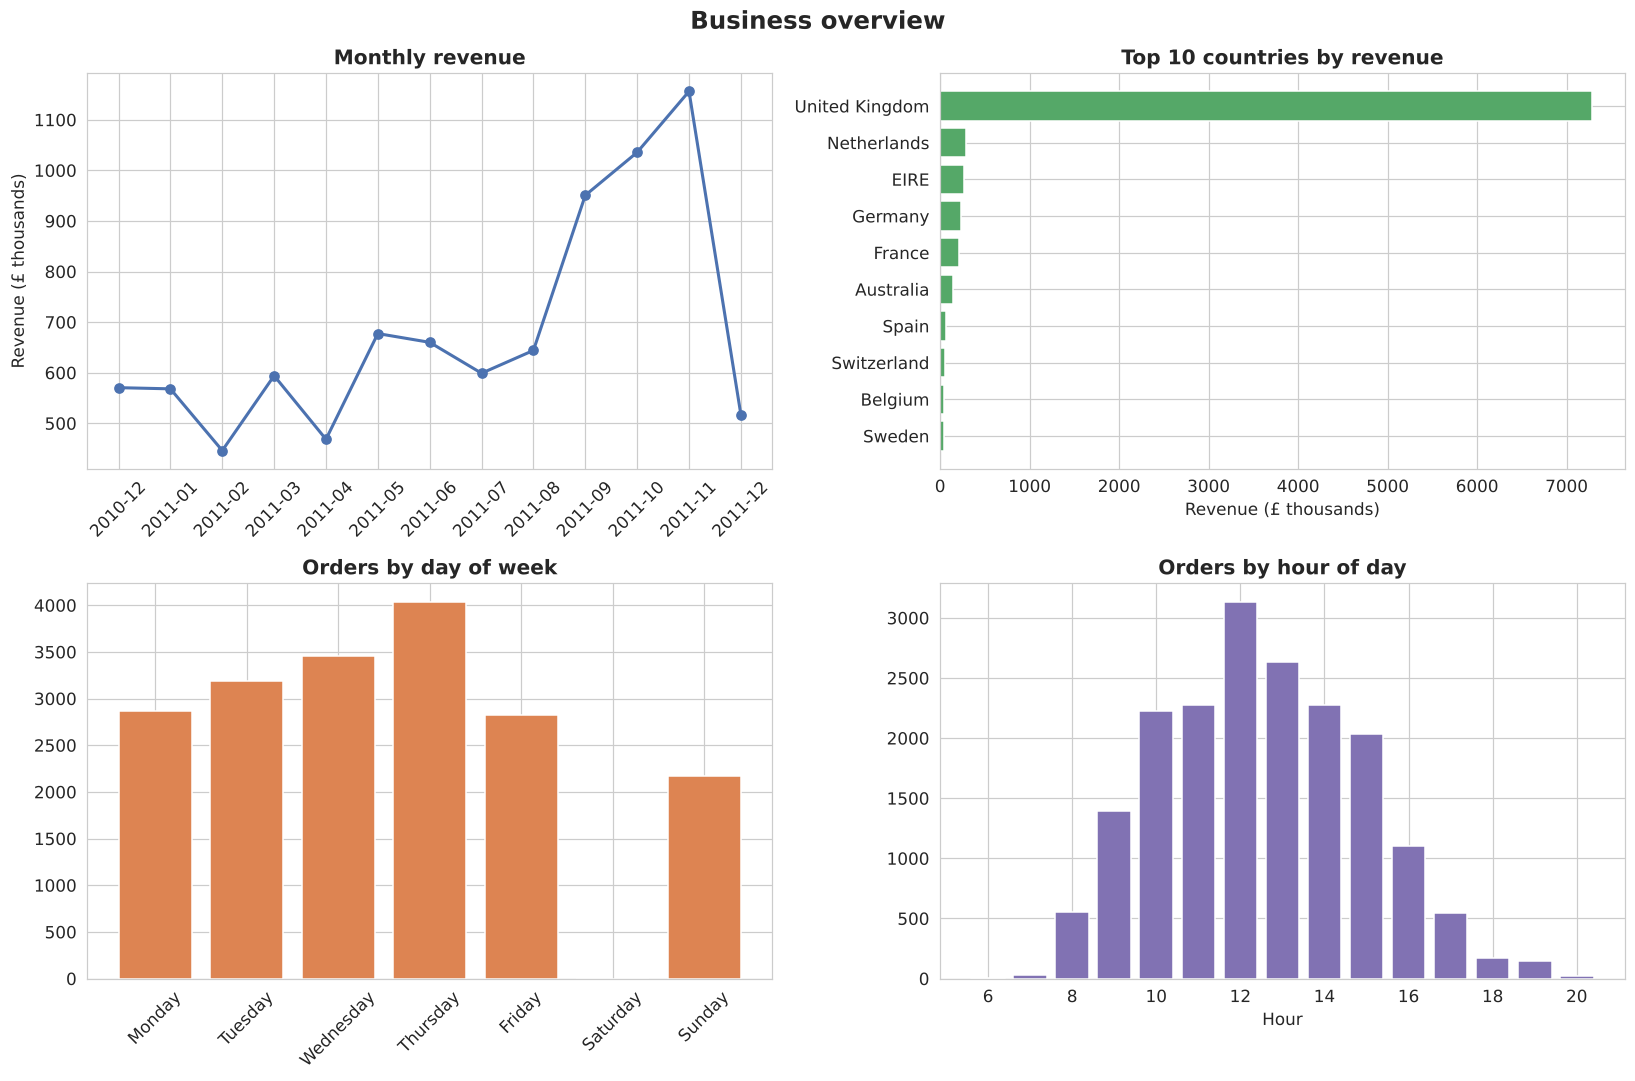

Peak revenue month: 2011-11 (£1,156,206)
Top country: United Kingdom (82.0% of revenue)
Busiest day: Thursday | Saturday orders: 0
Peak hour: 12:00


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

monthly_revenue = df.groupby(df['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()
axes[0, 0].plot(monthly_revenue.index.astype(str), monthly_revenue.values / 1e3, marker='o', color='#4C72B0', linewidth=2)
axes[0, 0].set_title('Monthly revenue', fontweight='bold')
axes[0, 0].set_ylabel('Revenue (£ thousands)')
axes[0, 0].tick_params(axis='x', rotation=45)

country_revenue = df.groupby('Country')['Revenue'].sum().sort_values().tail(10)
axes[0, 1].barh(country_revenue.index, country_revenue.values / 1e3, color='#55A868')
axes[0, 1].set_title('Top 10 countries by revenue', fontweight='bold')
axes[0, 1].set_xlabel('Revenue (£ thousands)')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
orders_by_day = df.groupby(df['InvoiceDate'].dt.day_name())['InvoiceNo'].nunique().reindex(day_order).fillna(0)
axes[1, 0].bar(orders_by_day.index, orders_by_day.values, color='#DD8452')
axes[1, 0].set_title('Orders by day of week', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45)

orders_by_hour = df.groupby(df['InvoiceDate'].dt.hour)['InvoiceNo'].nunique()
axes[1, 1].bar(orders_by_hour.index, orders_by_hour.values, color='#8172B3')
axes[1, 1].set_title('Orders by hour of day', fontweight='bold')
axes[1, 1].set_xlabel('Hour')

plt.suptitle('Business overview', fontsize=16, fontweight='bold')
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/business_overview.png', bbox_inches='tight')
plt.show()

print(f"Peak revenue month: {monthly_revenue.idxmax()} (£{monthly_revenue.max():,.0f})")
print(f"Top country: {country_revenue.index[-1]} ({country_revenue.values[-1] / total_revenue * 100:.1f}% of revenue)")
print(f"Busiest day: {orders_by_day.idxmax()} | Saturday orders: {int(orders_by_day['Saturday'])}")
print(f"Peak hour: {orders_by_hour.idxmax()}:00")

## 7. RFM features

In [8]:
reference_date = df['InvoiceDate'].max() + timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (reference_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
).reset_index()

# Keep actual spend for reporting; use a capped copy for clustering only
monetary_cap = rfm['Monetary'].quantile(0.99)
rfm['Monetary_capped'] = rfm['Monetary'].clip(upper=monetary_cap)

print(f"Reference date: {reference_date.date()} | Customers: {len(rfm):,}")
print(f"Monetary 99th percentile cap (clustering only): £{monetary_cap:,.2f}")
print(f"Customers above the cap: {(rfm['Monetary'] > monetary_cap).sum()}")
print(f"Customers with one order: {(rfm['Frequency'] == 1).sum():,} ({(rfm['Frequency'] == 1).mean() * 100:.1f}%)")
print(f"Active in the last 30 days: {(rfm['Recency'] <= 30).sum():,} | Inactive over 180 days: {(rfm['Recency'] > 180).sum():,}")
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(1)

Reference date: 2011-12-10 | Customers: 4,338
Monetary 99th percentile cap (clustering only): £19,780.49
Customers above the cap: 44
Customers with one order: 1,493 (34.4%)
Active in the last 30 days: 1,648 | Inactive over 180 days: 860


,Recency,Frequency,Monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7
std,100.0,7.7,8985.2
min,1.0,1.0,3.8
25%,18.0,1.0,306.5
50%,51.0,2.0,668.6
75%,142.0,5.0,1660.6
max,374.0,209.0,280206.0


## 8. K-Means clustering

Frequency and Monetary are heavily right-skewed, so both are log-transformed before scaling. The number of segments is chosen from the elbow curve and silhouette scores together with business usefulness.

k=2: WCSS=6,814  silhouette=0.4074


k=3: WCSS=4,247  silhouette=0.4157


k=4: WCSS=3,195  silhouette=0.3784


k=5: WCSS=2,715  silhouette=0.3443


k=6: WCSS=2,346  silhouette=0.3346


k=7: WCSS=2,124  silhouette=0.3274


k=8: WCSS=1,920  silhouette=0.2977


k=9: WCSS=1,787  silhouette=0.2982


k=10: WCSS=1,650  silhouette=0.2808


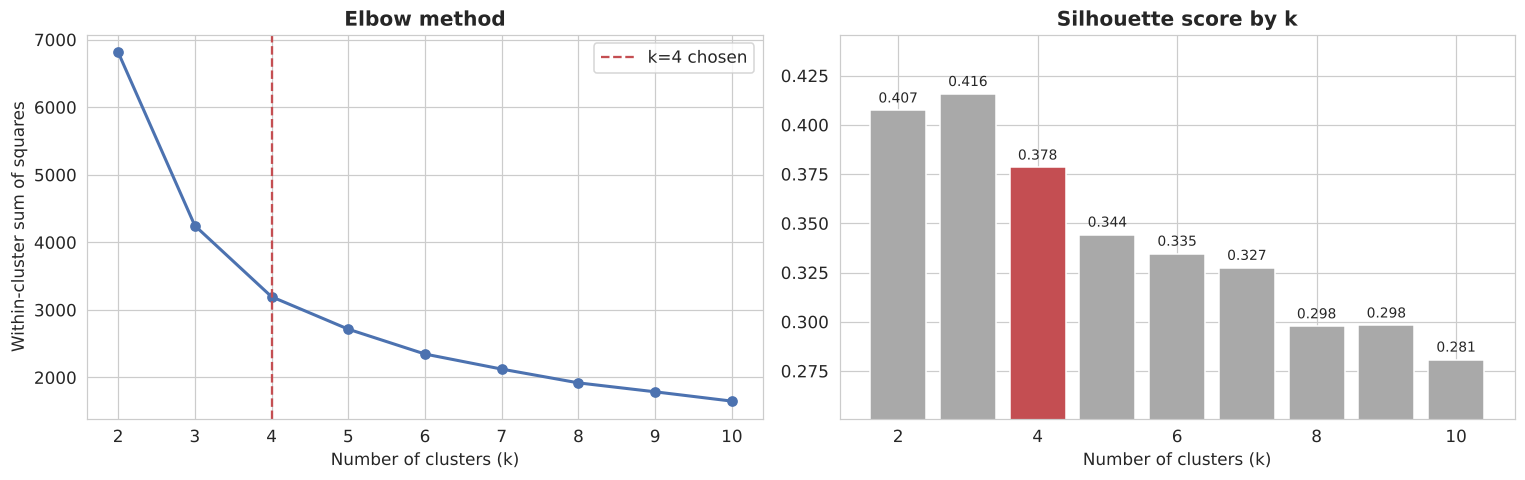

Highest silhouette: k=3 (0.4157) | chosen k=4 (0.3784)


In [9]:
rfm['Frequency_log'] = np.log1p(rfm['Frequency'])
rfm['Monetary_log'] = np.log1p(rfm['Monetary_capped'])
features = ['Recency', 'Frequency_log', 'Monetary_log']
rfm_scaled = StandardScaler().fit_transform(rfm[features])

k_values = list(range(2, 11))
wcss, sil_scores = [], []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(rfm_scaled)
    wcss.append(model.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, model.labels_))
    print(f"k={k}: WCSS={model.inertia_:,.0f}  silhouette={sil_scores[-1]:.4f}")

CHOSEN_K = 4
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(k_values, wcss, marker='o', color='#4C72B0', linewidth=2)
axes[0].axvline(CHOSEN_K, color='#C44E52', linestyle='--', label=f'k={CHOSEN_K} chosen')
axes[0].set_title('Elbow method', fontweight='bold')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Within-cluster sum of squares')
axes[0].legend()

bar_colors = ['#C44E52' if k == CHOSEN_K else '#A9A9A9' for k in k_values]
axes[1].bar(k_values, sil_scores, color=bar_colors)
for k, score in zip(k_values, sil_scores):
    axes[1].text(k, score + 0.004, f'{score:.3f}', ha='center', fontsize=9)
axes[1].set_title('Silhouette score by k', fontweight='bold')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylim(min(sil_scores) - 0.03, max(sil_scores) + 0.03)
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/elbow_silhouette.png', bbox_inches='tight')
plt.show()

best_k = k_values[int(np.argmax(sil_scores))]
print(f"Highest silhouette: k={best_k} ({max(sil_scores):.4f}) | chosen k={CHOSEN_K} ({sil_scores[k_values.index(CHOSEN_K)]:.4f})")

**Why k=4 rather than the highest silhouette score:** k=3 scores slightly higher, but it merges recent one-time buyers with long-lapsed ones. Those groups look the same on frequency and spend and differ only on recency, yet they need opposite actions (activation vs. win-back). k=4 keeps them apart, the elbow flattens around 4, and the silhouette score stays close.

In [10]:
final_model = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
rfm['Cluster'] = final_model.fit_predict(rfm_scaled)
print(f"Silhouette (k={CHOSEN_K}): {silhouette_score(rfm_scaled, rfm['Cluster']):.4f}")
print(rfm['Cluster'].value_counts().sort_index().to_string())

Silhouette (k=4): 0.3784
Cluster
0    1366
1     595
2     938
3    1439


## 9. Segment profiles

Segments are labeled by ranking each cluster on recency, frequency and spend. Revenue totals and shares use **actual, uncapped spend**.

In [11]:
profile = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Spend=('Monetary', 'mean'),
    Median_Spend=('Monetary', 'median'),
    Revenue=('Monetary', 'sum'),
)
profile['Customer_Share_%'] = profile['Customers'] / profile['Customers'].sum() * 100
profile['Revenue_Share_%'] = profile['Revenue'] / profile['Revenue'].sum() * 100

rank = (profile['Avg_Recency'].rank()
        + profile['Avg_Frequency'].rank(ascending=False)
        + profile['Avg_Spend'].rank(ascending=False))
labels = ['Champions', 'Promising', 'New/Occasional', 'At-Risk/Lapsed']
segment_labels = {key: value for key, value in zip(rank.sort_values().index, labels)}

rfm['Segment'] = rfm['Cluster'].map(segment_labels)
profile.index = profile.index.map(segment_labels)
profile = profile.loc[labels]

print(f"Revenue check: segments sum to £{profile['Revenue'].sum():,.0f} vs total £{total_revenue:,.0f}")
profile.round(1)

Revenue check: segments sum to £8,887,209 vs total £8,887,209


,Customers,Avg_Recency,Avg_Frequency,Avg_Spend,Median_Spend,Revenue,Customer_Share_%,Revenue_Share_%
Cluster,,,,,,,,
Champions,595,19.0,15.5,9111.6,4331.8,5421413.8,13.7,61.0
Promising,1439,46.9,4.1,1745.5,1304.8,2511817.8,33.2,28.3
New/Occasional,1366,57.9,1.5,378.1,337.6,516537.7,31.5,5.8
At-Risk/Lapsed,938,259.6,1.4,466.4,294.2,437439.6,21.6,4.9


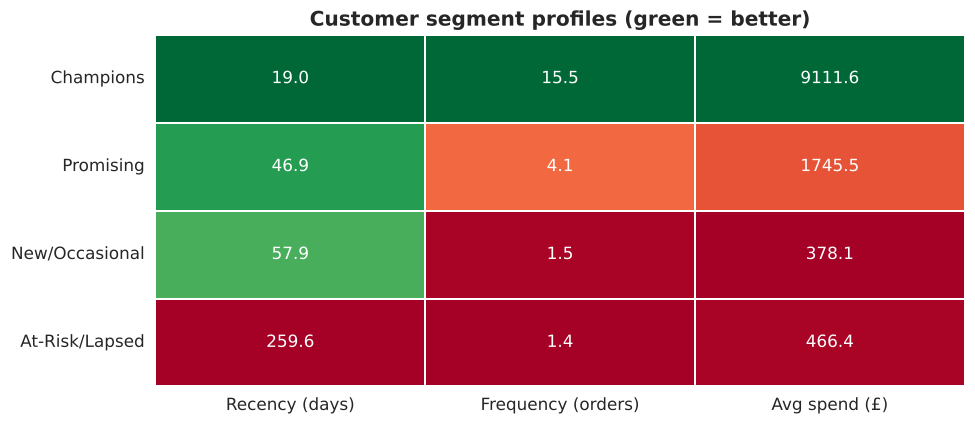

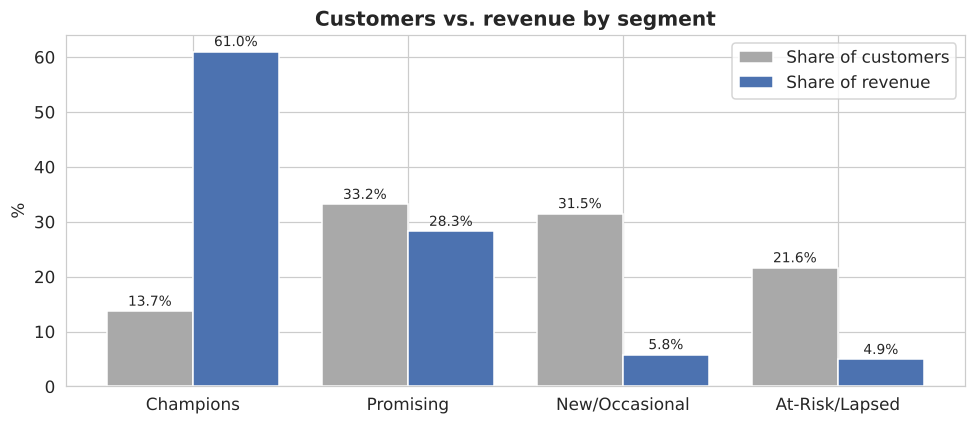

In [12]:
heat = profile[['Avg_Recency', 'Avg_Frequency', 'Avg_Spend']].copy()
heat.columns = ['Recency (days)', 'Frequency (orders)', 'Avg spend (£)']
scaled = (heat - heat.min()) / (heat.max() - heat.min())
scaled['Recency (days)'] = 1 - scaled['Recency (days)']   # fewer days = better

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(scaled, annot=heat.round(1).values, fmt='', cmap='RdYlGn', linewidths=1, cbar=False, ax=ax)
ax.set_title('Customer segment profiles (green = better)', fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/segment_heatmap.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(labels))
ax.bar(x - 0.2, profile['Customer_Share_%'], width=0.4, label='Share of customers', color='#A9A9A9')
ax.bar(x + 0.2, profile['Revenue_Share_%'], width=0.4, label='Share of revenue', color='#4C72B0')
for i, (key, value) in enumerate(zip(profile['Customer_Share_%'], profile['Revenue_Share_%'])):
    ax.text(i - 0.2, key + 1, f'{key:.1f}%', ha='center', fontsize=9)
    ax.text(i + 0.2, value + 1, f'{value:.1f}%', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('%')
ax.set_title('Customers vs. revenue by segment', fontweight='bold')
ax.legend()
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/segment_revenue_share.png', bbox_inches='tight')
plt.show()

## 10. Recommendations by segment

In [13]:
seg = profile  # shorthand
champ, prom, new, lapsed = (seg.loc[label] for label in labels)

def header(label, row, priority):
    print('-' * 80)
    print(f"{label.upper()}: {int(row['Customers']):,} customers ({row['Customer_Share_%']:.1f}%) | "
          f"£{row['Revenue']:,.0f} revenue ({row['Revenue_Share_%']:.1f}%)")
    print(f"Avg recency {row['Avg_Recency']:.0f} days | avg frequency {row['Avg_Frequency']:.1f} orders | "
          f"avg spend £{row['Avg_Spend']:,.0f}")
    print(f"Priority: {priority}")

header('Champions', champ, 'RETAIN: losing even one Champion has outsized revenue impact')
print("- VIP loyalty program with early access to new product lines")
print("- Dedicated account management for the top 50 Champions by spend")
print("- Referral incentives and personalized thank-you communications")
print("- Quarterly business reviews for wholesale Champions; Sept/Oct loyalty rewards ahead of Q4")
print(f"KPI: Champion retention rate (target >95% quarter over quarter)")
print(f"Revenue at risk if 10% of Champions churn: ~£{0.10 * champ['Revenue']:,.0f}")

header('Promising', prom, 'GROW: convert into future Champions')
print("- Cross-sell campaigns based on purchase history")
print("- Free-shipping threshold set above the average order value")
print("- Milestone rewards at the 5th, 10th and 15th order")
print("- Re-engagement email if no order within 45 days")
upgrade_customers = round(0.10 * prom['Customers'])
# Medians, because a few very large wholesale accounts inflate the Champion average
upside = upgrade_customers * (champ['Median_Spend'] - prom['Median_Spend'])
print(f"KPI: Promising -> Champions migration (target 8-15% a year)")
print(f"Upside if 10% upgrade ({upgrade_customers} customers moving from Promising to Champion median spend): ~£{upside:,.0f}")

header('New/Occasional', new, 'ACTIVATE: turn first-time buyers into repeat customers')
print("- Post-purchase email sequence: thank you -> product tips -> related items")
print("- Second-purchase offer (10-15% off within 30 days)")
print("- Buy-again reminders for seasonal items; September activation before the Q4 rush")
print(f"KPI: second-purchase conversion (target 25% within 60 days)")
print(f"Each 1-point lift in conversion = ~{round(0.01 * new['Customers'])} more repeat customers")

header('At-Risk/Lapsed', lapsed, 'EVALUATE: one structured win-back attempt, then redirect budget')
print("- One win-back campaign with a strong offer (25-30% off), timed for October")
print("- Short survey to learn why they left")
print("- No response after two attempts: reduce spend and redirect budget to Champions")

--------------------------------------------------------------------------------
CHAMPIONS: 595 customers (13.7%) | £5,421,414 revenue (61.0%)
Avg recency 19 days | avg frequency 15.5 orders | avg spend £9,112
Priority: RETAIN: losing even one Champion has outsized revenue impact
- VIP loyalty program with early access to new product lines
- Dedicated account management for the top 50 Champions by spend
- Referral incentives and personalized thank-you communications
- Quarterly business reviews for wholesale Champions; Sept/Oct loyalty rewards ahead of Q4
KPI: Champion retention rate (target >95% quarter over quarter)
Revenue at risk if 10% of Champions churn: ~£542,141
--------------------------------------------------------------------------------
PROMISING: 1,439 customers (33.2%) | £2,511,818 revenue (28.3%)
Avg recency 47 days | avg frequency 4.1 orders | avg spend £1,746
Priority: GROW: convert into future Champions
- Cross-sell campaigns based on purchase history
- Free-shipping

### Win-back ROI check

Assumptions are explicit so they can be changed: contact cost per customer, reactivation rate, how much of their past spend returning customers spend again, and the discount given.

In [14]:
CONTACT_COST = 2.00   # £ per customer contacted

def win_back(reactivation_rate, spend_ratio, discount):
    contacted = lapsed['Customers']
    reactivated = contacted * reactivation_rate
    revenue = reactivated * lapsed['Avg_Spend'] * spend_ratio * (1 - discount)
    cost = contacted * CONTACT_COST
    return reactivated, revenue, cost

for name, params in {'Optimistic': (0.05, 1.0, 0.0), 'Conservative': (0.03, 0.7, 0.30)}.items():
    reactivated, revenue, cost = win_back(*params)
    print(f"{name:12s}: {reactivated:.0f} customers return -> £{revenue:,.0f} revenue vs £{cost:,.0f} cost "
          f"= {revenue / cost:.1f}x")

Optimistic  : 47 customers return -> £21,872 revenue vs £1,876 cost = 11.7x
Conservative: 28 customers return -> £6,430 revenue vs £1,876 cost = 3.4x


## 11. Budget allocation and key insights

In [15]:
budget = {'Champions (retain)': 40, 'Promising (grow)': 30, 'New/Occasional (activate)': 20, 'At-Risk/Lapsed (win back)': 10}
for key, value in budget.items():
    print(f"{key:28s} {value}%")
print(f"\nSeasonal note: revenue peaks in {monthly_revenue.idxmax().strftime('%B')}; weight campaign spend toward Sept-Nov.")

print("\nKEY INSIGHTS")
print(f"1. {champ['Customer_Share_%']:.1f}% of customers (Champions) generate {champ['Revenue_Share_%']:.1f}% of revenue: retention beats acquisition.")
print(f"2. Promising is the growth pipeline: a 10% upgrade adds ~£{upside:,.0f}.")
print(f"3. New/Occasional and At-Risk/Lapsed look alike on frequency ({new['Avg_Frequency']:.1f} vs {lapsed['Avg_Frequency']:.1f} orders) "
      f"and differ on recency ({new['Avg_Recency']:.0f} vs {lapsed['Avg_Recency']:.0f} days), so they need different actions.")
print("4. Track Net Segment Migration = (Promising -> Champions) - (Champions -> At-Risk/Lapsed) each month.")

Champions (retain)           40%
Promising (grow)             30%
New/Occasional (activate)    20%
At-Risk/Lapsed (win back)    10%

Seasonal note: revenue peaks in November; weight campaign spend toward Sept-Nov.

KEY INSIGHTS
1. 13.7% of customers (Champions) generate 61.0% of revenue: retention beats acquisition.
2. Promising is the growth pipeline: a 10% upgrade adds ~£435,885.
3. New/Occasional and At-Risk/Lapsed look alike on frequency (1.5 vs 1.4 orders) and differ on recency (58 vs 260 days), so they need different actions.
4. Track Net Segment Migration = (Promising -> Champions) - (Champions -> At-Risk/Lapsed) each month.
